# **Cafés Baixa Pombalina**

-

**OBJETIVO:** Responder a pergunta quantos cafés existem na Baixa Pombalina de Lisboa?

-


**1. DEFINIÇÕES CONCEITUAIS**


**1.1. O que é a Baixa Pombalina?**

A Baixa Pombalina, também conhecida como Baixa de Lisboa ou Lisboa Pombalina, é uma área central e histórica da cidade de Lisboa. O nome Pombalina é uma referência ao Marquês de Pombal, Secretário de Estado do rei D. José I, que foi o responsável pela reconstrução da região após o terramoto de 1755. Com uma área de aproximadamente 2,55 km², a Baixa Pombalina abrange importantes pontos turísticos como o Terreiro do Paço, junto ao rio Tejo, o Rossio e a Praça da Figueira. Longitudinalmente, está situada entre o Cais do Sodré, o Chiado e o Carmo, de um lado, e a Sé e a colina do Castelo de São Jorge, do outro (1,2,3).

Para definir com maior precisão os limites geográficos da região da Baixa Pombalina, foi realizada uma revisão da literatura sobre a história e as características da área. A seguir, são apresentadas duas figuras que ilustram a delimitação dessa região:

Figura 1: Limites da Baixa Pombalina (Plano do Marquês de Pombal)

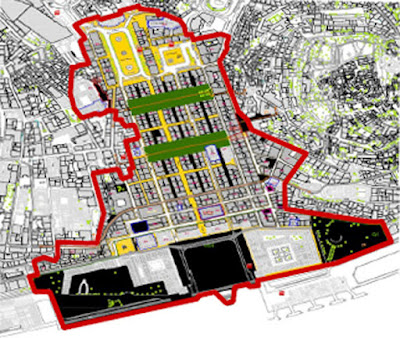

Fonte: Carrasco, Carlos, 2015.(1)

Figura 2: Limites da Baixa Pombalina (Diáro da República 2011)

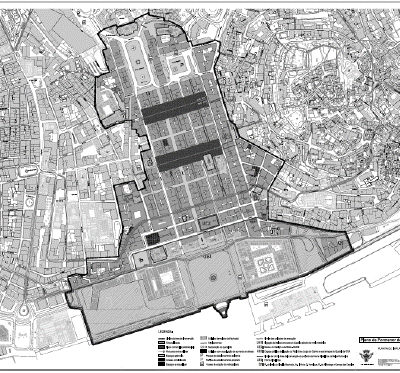

Fonte: Reis, Vasco & Escarameia, Alexandra & Macário, Rosário, 2019.(2)

**1.2. Limites Geográficos:**

Com base em uma revisão bibliográfica, constatou-se que a Baixa Pombalina está localizada nas coordenadas: 38.7138, -9.1399. No entanto, para este trabalho, a fim de proporcionar uma delimitação mais precisa da área em estudo, foram definidas as seguintes coordenadas geográficas para delimitar toda a região:

- Cais do Sodré: 38.7066, -9.14352
- Chiado: 38.71054, -9.1422
- Carmo: 38.71186, -9.14101
- Rossio: 38.71386, -9.13936
- Praça da Figueira: 38.71348, -9.13813
- Sé de Lisboa: 38.70983, -9.13295
- Terreiro do Paço: 38.707, -9.1336
- Rua da Prata: 38.712600, -9.135510
- Rua Augusta: 38.714210, -9.135930
- Avenida da Liberdade: 38.715730, -9.139280
- Rua dos Fanqueiros: 38.714330, -9.141520

Com base nessas coordenadas, desenhou-se um polígono ao redor das regiões mencionadas, cujo resultado pode ser visualizado na figura abaixo:

Figura 3: Limites da Baixa Pombalina (recorte geográfico com base nas coordenadas definidas)

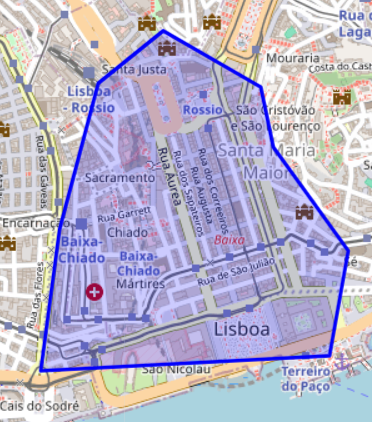

Fonte: Elaborado pelo Autor, 2024.



**1.2. O que é um Café?**

Um café, também chamado de cafeteria ou cafetaria, é um estabelecimento que serve café, chá e outras bebidas, além de refeições leves como sanduíches e pratos combinados.

No âmbito deste trabalho, para definir o estabelecimento "Café" na API da TomTom foi realizada uma consulta a todas os Pontos de Interesse (POI). E identificou-se que apenas dois POI's eram relevantes para a busca:

- "id": 7315, "name": "Restaurant"
- "id": 9376, "name": "Café/Pub"

Diante disso, foram realizados dois testes: um utilizando o POI "Café/Pub" e outro o "Restaurant". O teste com "Café/Pub" resultou em 55 estabelecimentos, mas muitos desses eram bares e cervejarias, que não se enquadravam no conceito de café definido neste trabalho. Por outro lado, o teste com a categoria "Restaurant" retornou 94 estabelecimentos, todos correspondentes a cafés.

Assim, optou-se pela utilização do POI "Restaurant" (id: 7315), por oferecer resultados mais alinhados com a definição de um café.

**2. API DA TOMTOM**

**2.1. Como obter uma lista dos cafés contornando possíveis limitações da API? (*Resourcefulness*)**

Para obter uma lista dos cafés na API (*Application Programming Interface*) da TomTom foram realizados diversos testes e o que apresentou melhor resultado foi atravéz da Search API CategorySearch, com os seguintes parâmetros:

- Query string: cafe
- ext: Json
- Latitude: 38.7138
- Longitude: -9.1399
- categorySet: 7315

Optou-se por escolher as coordenadas de localização do centro da Baixa Pombalina (38.7138, -9.1399) e posteriormente filtrar os estabelecimentos que se encontravam dentro e fora da região da Baixa Pombalina (Figura 3). Esta opção foi escolhida pois os testes feitos com as coordenadas de localização dos pontos principais da região retornaram estabelecimentos que ficavam muito distantes da região da Baixa Pombalina (ex: estabelecimentos em santos e outras zonas).

A principal limitação da API está no parâmetro 'limit', que é configurado para retornar no máximo 100 cafés por requisição. No entanto, como o número de cafés encontrados dentro do raio de busca foi de apenas 94, não houve necessidade de implementar uma estratégia de paginação para recuperar mais de 100 resultados. Outra limitação da API é a falta de um tratamento de erros. A API apenas permite que o código exiba uma mensagem em caso de falha na requisição. No entanto, essa limitação não impactou o desenvolvimento deste trabalho, já que nenhuma falha ocorreu durante a execução.



In [1]:
# 3. LEVANTAMENTO DOS DADOS

#O objetivo deste levantamento de dados é localizar e listar os cafés situados dentro do raio de 1 km ao redor da Baixa Pombalina,
#utilizando a API da TomTom para fazer consultas com base em coordenadas geográficas, retornando e armazenando os resultados.


import requests #importação da biblioteca 'request', utilizada para fazer requisições HTTP, permitindo que o programa interaja com a API da TomTom.

# Chave de API da TomTom - necessária para autenticar as requisições feitas.
api_key = 'GL0ccFcR1i20GxoWc9xIlrGKPTTD922m'

# Coordenadas do centro da Baixa Pombalina.
latitude = 38.7138
longitude = -9.1399

# Endpoint da Search API para buscar pontos de interesse (POIs) configurado para procurar especificamente por cafés.
url = f'https://api.tomtom.com/search/2/search/cafe.json'

# A Função 'get_cafes' faz a requisição à API busca e retorna cafés dentro de 1 km ao redor da coordenada.

#Execução: Esta função monta um dicionário 'params' com os parâmetros de busca, incluindo a chave da API, as coordenadas de latitude e longitude, o raio,
#e um identificador de categoria (categorySet = '7315') que corresponde a cafés. Faz uma requisição GET para o endpoint da API utilizando esses parâmetros.
#Se a resposta da API for bem-sucedida (status code 200), os resultados são armazenados na variável 'cafes', o código imprime a quantidade de cafés encontrados
#e, em seguida, percorre a lista de cafés, imprimindo o nome e o endereço de cada um. Caso contrário, um erro é impresso.

def get_cafes(lat, lon, radius, api_key):
    params = {
        'key': api_key, #Chave de API da TomTom para autenticar a requisição.
        'lat': lat, #Latitude do centro de busca.
        'lon': lon, # Longitude do centro de busca.
        'radius': radius,  # Raio da área de de busca em metros.
        'categorySet': '7315',  # Categoria para cafés.
        'limit': 100  # Limite de resultados por requisição.
    }
    response = requests.get(url, params=params)
    if response.status_code == 200:
        return response.json().get('results', [])
    else:
        print("Erro ao obter os dados:", response.status_code, response.text)
        return []

# Obter cafés em múltiplas requisições para cobrir toda a área.
cafes = get_cafes(latitude, longitude, 1000, api_key)  # Raio de 1 km cobre toda a região definida.

#Exibir resultados.
print(f"RESULTADO: Foram encontrados {len(cafes)} cafés em um raio de 1 km ao redor da Baixa Pombalina, em Lisboa.")


Erro ao obter os dados: 401 {"detailedError":{"code":"Unauthorized","message":"You are missing valid authentication credentials"}}
RESULTADO: Foram encontrados 0 cafés em um raio de 1 km ao redor da Baixa Pombalina, em Lisboa.


In [2]:
# 4. TRATAMENTO DOS DADOS

#O objetivo deste tratamento de dados é filtrar, dos 94 cafés encontrados, aqueles que estão localizados dentro dos limites da Baixa Pombalina.

import folium #biblioteca utilizada para criar e visualizar mapas interativos.
from shapely.geometry import Point, Polygon #biblioteca para a manipulação e análise de formas geométricas.

# Coordenadas do polígono da Baixa Pombalina.
area_coords = [              #define os vértices do polígono que circunscreve a área da Baixa Pombalina.
    (-9.142860, 38.710400),  # Ponto próximo ao Cais do Sodré.
    (-9.14352, 38.7066),     # Cais do Sodré.
    (-9.1336, 38.707),       # Terreiro do Paço.
    (-9.13295, 38.70983),    # Sé de Lisboa.
    (-9.135510, 38.712600),  # Rua da Prata.
    (-9.135930, 38.714210),  # Rua Augusta.
    (-9.139280, 38.715730),  # Avenida da Liberdade.
    (-9.141520, 38.714330),  # Rua dos Fanqueiros.
    (-9.142860, 38.710400)   # Fechando o polígono.
]

# Criar o polígono da Baixa Pombalina com as coordenadas definidas anteriormente.
polygon = Polygon(area_coords)

# Criar uma lista onde os dados serão armazenados.
cafes_lista = []

# Criar um loop 'for' para iterar sobe a lista de cafes e para cada café, extrair o nome, endereço, latitude e longitude. Esses dados serão organizados em um dicionário e adicionados à 'cafes_lista'.
for cafe in cafes:
    name = cafe['poi']['name']
    address = cafe['address']['freeformAddress']
    lat = cafe['position']['lat']
    lon = cafe['position']['lon']

# Adicionar o café à lista.
    cafes_lista.append({
        'name': name,
        'address': address,
        'latitude': lat,
        'longitude': lon
    })

# Filtrar os cafés que estão dentro do polígono.
#A lista 'cafes_dentro' armazena os cafés cujas coordenadas estão dentro do polígono definido. E a função 'polygon.contains()' verifica se o ponto está dentro do polígono.

cafes_dentro = [
    cafe for cafe in cafes_lista if polygon.contains(Point(cafe['longitude'], cafe['latitude']))
]

# Filtrar os cafés que estão fora do polígono (lógica inversa do filtro anterior - 'cafes-dentro').
cafes_fora = [
    cafe for cafe in cafes_lista if not polygon.contains(Point(cafe['longitude'], cafe['latitude']))
]

print(f"RESULTADO:")
print(f"{len(cafes_fora)} cafés excluídos por estarem fora dos limites da Baixa Pombalina.")
print(f"{len(cafes_dentro)} cafés incluídos por estarem dentro dos limites da Baixa Pombalina.")

RESULTADO:
0 cafés excluídos por estarem fora dos limites da Baixa Pombalina.
0 cafés incluídos por estarem dentro dos limites da Baixa Pombalina.


In [3]:
#5. APRESENTAÇÃO DOS RESULTADOS

#5.1: Visualização no Mapa

#O objetivo é apresentar um mapa interativo usando a biblioteca folium para exibir a distribuição dos cafés localizados dentro do polígono da Baixa Pombalina.

# Coordenadas do centro de Lisboa, utilizada para centralizar o mapa.
latitude = 38.7138
longitude = -9.1399

# Criar um mapa centralizado em Lisboa com a função 'folium.Map()'.
#'zoom_start' define o nível de zoom inicial do mapa. 15 é o valor de referência (suficiente para dar uma visão detalhada da área central de Lisboa).
mymap = folium.Map(location=[latitude, longitude], zoom_start=15)

# Adicionar o polígono ao mapa.
folium.Polygon(                                          # Desenhar o polígono da Baixa Pombalina no mapa.
    locations=[(lat, lon) for lon, lat in area_coords],  # As coordenadas de area_coords são invertidas para latitude, longitude porque o 'folium' espera esse formato.
    color='blue',                                        # Define que a cor das bordas do polígono será azul.
    fill=True,                                           # Define que o interior do polígono será preenchido.
    fill_color='blue',                                   # Define que a cor do interior do polígono será azul.
    fill_opacity=0.2,                                    # Define que a opacidade do preenchimento será de 0.2, permitindo ver o mapa por trás do polígono.
    popup="Baixa Pombalina e Áreas Adjacentes"           # Adiciona um popup interativo ao polígono com a descrição "Baixa Pombalina e Áreas Adjacentes".
).add_to(mymap)                                          # Adiciona o polígono ao mapa 'mymap'.

# Adicionar os cafés incluídos ao mapa.
for cafe in cafes_dentro:                                # Percorre a lista 'cafes_dentro'.
    folium.Marker(                                       # Adiciona um marcador no mapa para cada café.
        location=[cafe['latitude'], cafe['longitude']],  # Define a posição do marcador com as coordenadas latitude e longitude do café.
        popup=f"{cafe['name']}",                         # Adiciona um popup interativo ao marcador com o nome do café.
        icon=folium.Icon(icon="coffee", prefix='fa')     # Define o ícone do marcador como um ícone de café e um prefixo fa).
    ).add_to(mymap)                                      # Adiciona cada marcador de café ao mapa mymap.

# Salvar o mapa em um arquivo HTML chamado "cafes_map_baixa_pombalina_amplo.html".
mymap.save("cafes_map_baixa_pombalina_amplo.html")

# Exibir o mapa.
print(f"Mapa com localização de todos os Cafés da Baixa Pombalina")
mymap

Mapa com localização de todos os Cafés da Baixa Pombalina


In [4]:
from google.colab import files

# Save map in to a HTML file:
mymap.save("Mozambique_Species.html")
files.download("Mozambique_Species.html")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [5]:
#Para uma melhor visualização do mapa, é possível fazer o download do arquivo HTML e abri-lo em um navegador web.

from google.colab import files # Permite fazer upload e download de arquivos do Google Colab para o computador local.
files.download("cafes_map_baixa_pombalina_amplo.html") #faz o download do arquivo mapa "cafes_map_baixa_pombalina_amplo.html" para o computador local.

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [6]:
#5. APRESENTAÇÃO DOS RESULTADOS

#5.2: Lista dos Cafés da Baixa Pombalina.

#O objetivo é apresentar uma lista de todos os cafés que se encontram dentro dos limites da Baixa Pombalina.

print("Lista de Cafés da Baixa Pombalina:")

# Loop 'for' percorre cada café na lista 'cafes_dentro'. A função 'enumerate' retorna o índice (i) e o item (cafe) para cada iteração.
# O 'start=1' permite que o índice i comece em 1 (ao invés de 0, que é o padrão), para numerar os cafés a partir de 1.
# 'name', 'adress', 'lat', 'lon' são os dados extraídos do dicionário cafe.
# Para exibir a lista, optou-se por apresentar a numeração, o nome e o endereço dos cafés.

for i, cafe in enumerate(cafes_dentro, start=1):
    name = cafe['name']
    address = cafe['address']
    lat = cafe['latitude']
    lon = cafe['longitude']
    print(f"{i}. {name}, {address}")


Lista de Cafés da Baixa Pombalina:


**6. DISCUSSÃO**

-

Respondendo às questões: Como avaliar falsos positivos? Como estimar falsos negativos? Existem duplicados? (*Data Quality*)

-

**6.1 Tratamento de Falsos Positivos:**

Os resultados gerados (o mapa interativo e a lista de cafés) possibilitaram a verificação manual dos 37 estabelecimentos identificados, confirmando que todos eram, de fato, cafés e eliminando a possibilidade de falsos positivos.

**6.2. Tratamento de Falsos Negativos:**

O endpoint da Search API foi configurado para buscar especificamente por estabelecimentos com a palavra 'café' e/ou seus sinônimos. Como resultado, alguns locais que não possuem essas palavras em seus nomes, como o Starbucks localizado no Rossio, não foram incluídos no escopo deste trabalho. Para superar essa limitação, recomenda-se que pesquisas futuras incluam manualmente esses estabelecimentos ou explorem novas abordagens para identificá-los.

**6.3. Tratamento de Dados Duplicados:**

Como foi realizada uma única busca, não houve a identificação de resultados duplicados. Portanto, não foi necessário aplicar nenhum procedimento de tratamento para a remoção de dados repetidos.

**CONCLUSÃO**

Este trabalho alcançou o objetivo de determinar quantos cafés existem na Baixa Pombalina de Lisboa, utilizando uma abordagem baseada em API e técnicas de geoprocessamento de dados. Após o levantamento e tratamento dos dados, constatou-se que, dos 94 cafés inicialmente identificados, 37 estavam corretamente localizados dentro da área de interesse.

Conclui-se, portanto, que o método empregado foi eficaz na identificação dos estabelecimentos relevantes. No entanto, algumas limitações foram observadas, como o tratamento de falsos negativos e a necessidade de futuros ajustes manuais, para incluir os estabelecimentos não identificados pela API. Recomenda-se a realização de novas pesquisas para aprimorar a precisão e a eficiência do processo de coleta e tratamento de dados utilizando API's.




**REFERÊNCIAS**

(1) Carrasco, Carlos. HISTORIANDO: https://histgeo6.blogspot.com/2015/11/lisboa-pombalina.html. Data de acesso: 08/08/2024.

(2) Reis, Vasco & Escarameia, Alexandra & Macário, Rosário. (2019). Melhoria da Distribuição de Mercadorias na Baixa Pombalina de Lisboa – Perspetivas Sobre a Implementação de um Centro de Distribuição Urbana Para Servir o Segmento HORECA. RPER. 85-101. 10.59072/rper.vi50.504.

(3) WIKIPEDIA: https://pt.wikipedia.org/wiki/Baixa_de_Lisboa. Data de acesso: 08/08/2024.

(4) WIKIPEDIA: https://pt.wikipedia.org/wiki/Caf%C3%A9_(estabelecimento).  Data de acesso: 08/08/2024.

(6) TOMTOM. TomTom Maps API. Disponível em: https://developer.tomtom.com/maps-api. Data de acesso: 08/08/2024.